In [3]:
from paths import path_to_tiles_tensor_EAGLE_2016_corrected, path_to_tiles_tensor_IceBridge_HiCARS1_corrected, path_to_tiles_tensor_IceBridge_HiCARS2_corrected
from paths import path_to_tiles_metadata

from matplotlib.patches import Rectangle

In [4]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
tensor_EAGLE_2016_pc = torch.load(path_to_tiles_tensor_EAGLE_2016_corrected)
tensor_IceBridge_HiCARS1_pc = torch.load(path_to_tiles_tensor_IceBridge_HiCARS1_corrected)
tensor_IceBridge_HiCARS2_pc = torch.load(path_to_tiles_tensor_IceBridge_HiCARS2_corrected)

metadata = pd.read_csv(path_to_tiles_metadata)

In [6]:
tiles_pc = torch.cat([
    tensor_EAGLE_2016_pc,
    tensor_IceBridge_HiCARS1_pc,
    tensor_IceBridge_HiCARS2_pc], dim = 0)

print(f"Combined tensor shape: {tiles_pc.shape}")

Combined tensor shape: torch.Size([10815, 1, 336, 336])


In [7]:
top_mean = tiles_pc[:, :, :100, (168 - 20) : (168 + 20)].mean(dim = (1, 2, 3))

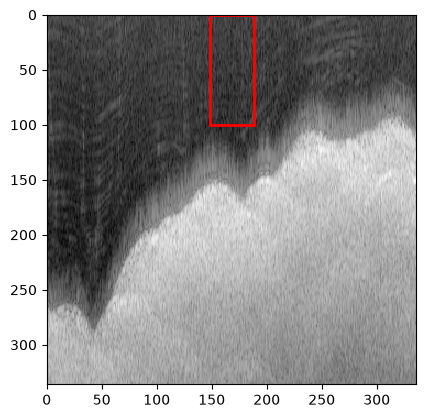

In [8]:
# define box
row_start, row_end = 0, 100
column_start, column_end = 168 - 20, 168 + 20

fig, ax = plt.subplots()
# Pass in 2D array
ax.pcolormesh(tiles_pc[5, 0, :, :], cmap = "gray")
ax.add_patch(Rectangle((column_start, row_start), column_end - column_start, row_end - row_start,
                       fill = False, edgecolor = "red", linewidth = 2))
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

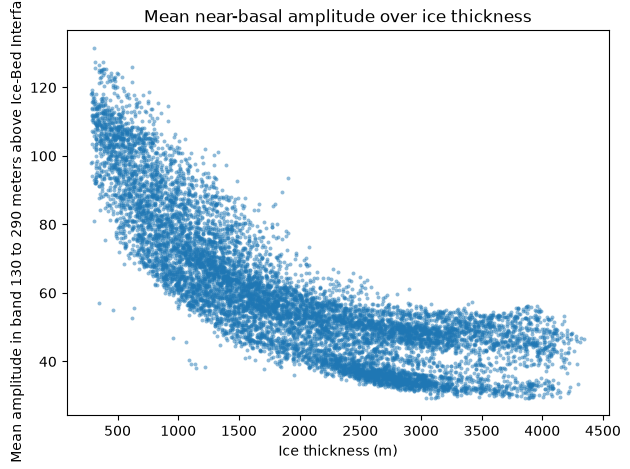

In [9]:
x = metadata["ice_thickness"].values
y = top_mean.numpy()

fig, ax = plt.subplots(figsize = (7, 5))
ax.scatter(x, y, s = 8, alpha = 0.5, linewidths = 0)
ax.set_xlabel("Ice thickness (m)")
ax.set_ylabel("Mean amplitude in band 130 to 290 meters above Ice-Bed Interface")
ax.set_title("Mean near-basal amplitude over ice thickness")
# ax.set_xlim(0, 4000)
plt.show()

In [10]:
metadata["survey"] == "ER2HI"

0         True
1         True
2         True
3         True
4         True
         ...  
10810    False
10811    False
10812    False
10813    False
10814    False
Name: survey, Length: 10815, dtype: bool

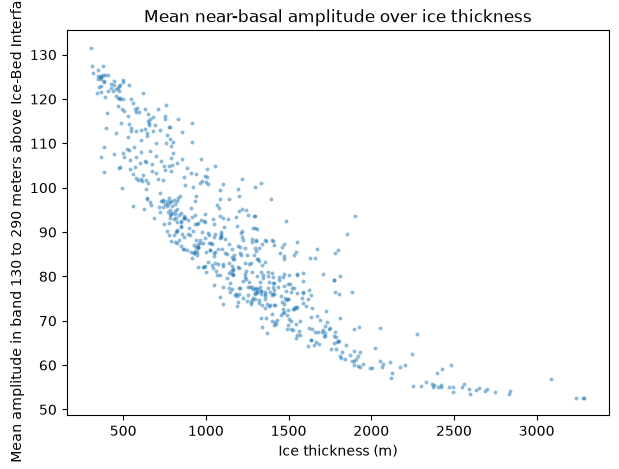

In [11]:
x = metadata["ice_thickness"].values[metadata["survey"] == "ER2HI"]
y = top_mean.numpy()[metadata["survey"] == "ER2HI"]

fig, ax = plt.subplots(figsize = (7, 5))
ax.scatter(x, y, s = 8, alpha = 0.5, linewidths = 0)
ax.set_xlabel("Ice thickness (m)")
ax.set_ylabel("Mean amplitude in band 130 to 290 meters above Ice-Bed Interface")
ax.set_title("Mean near-basal amplitude over ice thickness")
# ax.set_xlim(0, 4000)
plt.show()

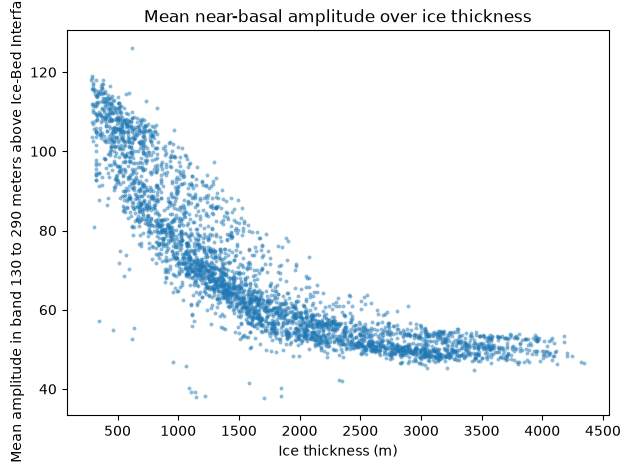

In [12]:
x = metadata["ice_thickness"].values[metadata["survey"] == "IR2HI"]
y = top_mean.numpy()[metadata["survey"] == "IR2HI"]

fig, ax = plt.subplots(figsize = (7, 5))
ax.scatter(x, y, s = 8, alpha = 0.5, linewidths = 0)
ax.set_xlabel("Ice thickness (m)")
ax.set_ylabel("Mean amplitude in band 130 to 290 meters above Ice-Bed Interface")
ax.set_title("Mean near-basal amplitude over ice thickness")
# ax.set_xlim(0, 4000)
plt.show()

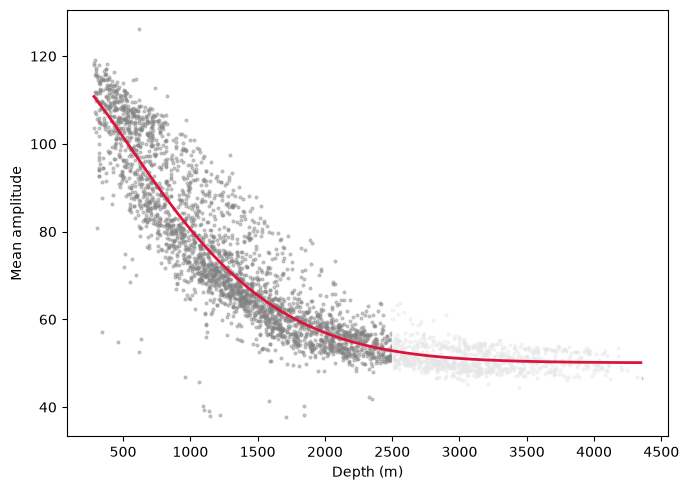

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

mask = metadata["survey"].values == "IR2HI"
x = metadata["ice_thickness"].values[mask].astype(float)
y = top_mean.numpy()[mask].astype(float)
ok = np.isfinite(x) & np.isfinite(y)
x, y = x[ok], y[ok]

def str_exp(z, a, L, beta, c):
    return a * np.exp(-(z / L) ** beta) + c

popt, _ = curve_fit(
    str_exp, x, y,
    p0 = [80, 1000, 0.7, 45],
    bounds = ([0, 10, 0.1, 0], [300, 1e4, 3, 100]),
    maxfev = 50000,
)

xx = np.linspace(x.min(), x.max(), 400)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, s=4, alpha=0.4, color = "grey")
ax.plot(xx, str_exp(xx, *popt), color="crimson", lw=2)
ax.axvspan(2500, x.max(), color="white", alpha=0.8)
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Mean amplitude")
plt.tight_layout()
plt.show()

{'a': np.float64(68.62900640966305), 'L': np.float64(1147.822994815583), 'beta': np.float64(1.5015191205717189), 'c': np.float64(50.09391203286024)}


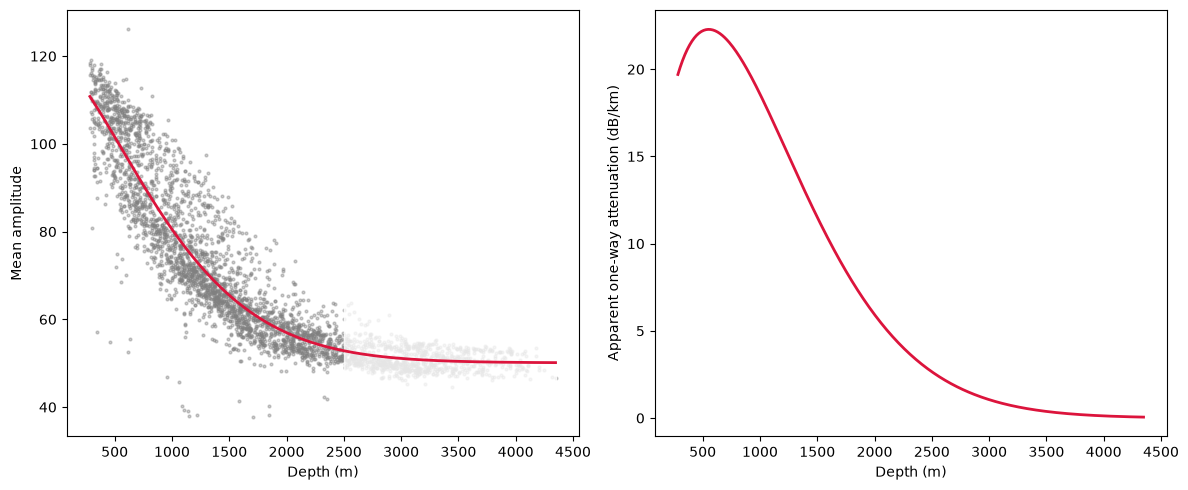

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

mask = metadata["survey"].values == "IR2HI"
x = metadata["ice_thickness"].values[mask].astype(float)
y = top_mean.numpy()[mask].astype(float)
ok = np.isfinite(x) & np.isfinite(y)
x, y = x[ok], y[ok]

def str_exp(z, a, L, beta, c):
    return a * np.exp(-(z / L) ** beta) + c

def str_exp_atten(z, a, L, beta, c):
    # one-way attenuation, -1/2 dP/dz, in dB/km (assumes y is power in dB, z in m)
    # c drops out in the derivative
    u = z / L
    return 1000 * a * beta / (2 * L) * u ** (beta - 1) * np.exp(-u ** beta)

popt, _ = curve_fit(
    str_exp, x, y,
    p0 = [80, 1000, 0.7, 45],
    bounds = ([0, 10, 0.1, 0], [300, 1e4, 3, 100]),
    maxfev = 50000,
)
print(dict(zip(["a", "L", "beta", "c"], popt)))

xx = np.linspace(x.min(), x.max(), 400)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

ax.scatter(x, y, s=4, alpha=0.4, color = "grey")
ax.plot(xx, str_exp(xx, *popt), color="crimson", lw=2)
ax.set_ylabel("Mean amplitude")

ax2.plot(xx, str_exp_atten(xx, *popt), color="crimson", lw=2)
ax2.set_ylabel("Apparent one-way attenuation (dB/km)")

for axis in (ax, ax2):
    axis.axvspan(2500, x.max(), color="white", alpha=0.8)
    axis.set_xlabel("Depth (m)")

plt.tight_layout()
plt.show()

{'a': np.float64(271.5804111763998), 'b': np.float64(27.763440122563964)}


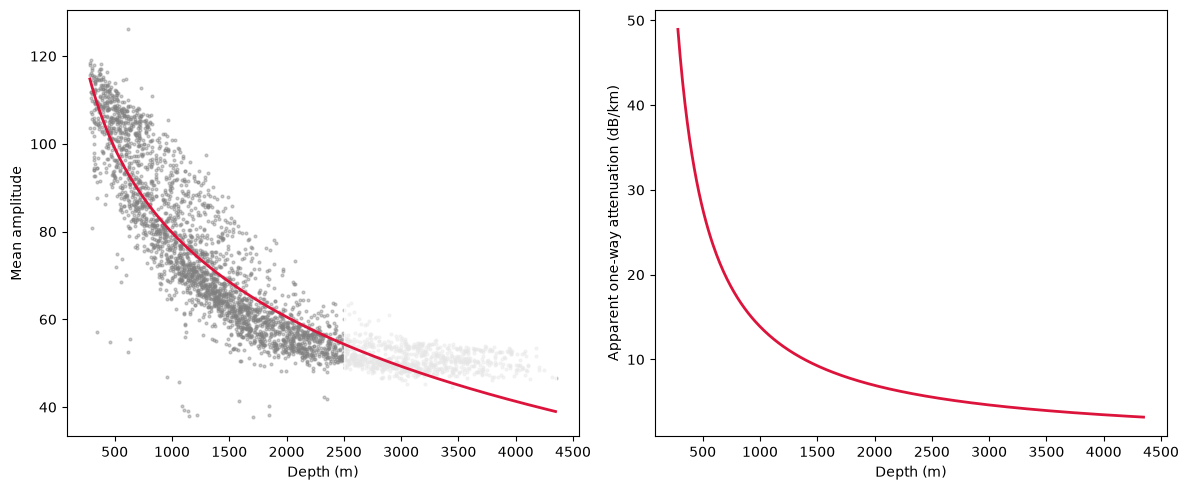

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

mask = metadata["survey"].values == "IR2HI"
x = metadata["ice_thickness"].values[mask].astype(float)
y = top_mean.numpy()[mask].astype(float)
ok = np.isfinite(x) & np.isfinite(y) & (x > 0)   # ln needs z > 0
x, y = x[ok], y[ok]

def neg_ln(z, a, b):
    return a - b * np.log(z)

def neg_ln_atten(z, a, b):
    # one-way attenuation, -1/2 dP/dz, in dB/km (y in dB, z in m)
    # a drops out in the derivative
    return 1000 * b / (2 * z)

popt, _ = curve_fit(neg_ln, x, y, p0 = [100, 10])
print(dict(zip(["a", "b"], popt)))

xx = np.linspace(x.min(), x.max(), 400)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

ax.scatter(x, y, s=4, alpha=0.4, color = "grey")
ax.plot(xx, neg_ln(xx, *popt), color="crimson", lw=2)
ax.set_ylabel("Mean amplitude")

ax2.plot(xx, neg_ln_atten(xx, *popt), color="crimson", lw=2)
ax2.set_ylabel("Apparent one-way attenuation (dB/km)")

for axis in (ax, ax2):
    axis.axvspan(2500, x.max(), color="white", alpha=0.8)
    axis.set_xlabel("Depth (m)")

plt.tight_layout()
plt.show()

a = 68.6, L = 1148 m, beta = 1.50, offset = 50.1


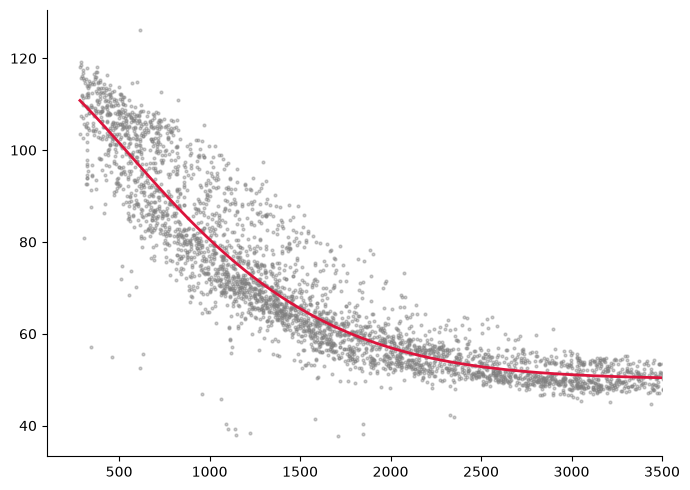

In [52]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

mask = metadata["survey"].values == "IR2HI"
x = metadata["ice_thickness"].values[mask].astype(float)
y = top_mean.numpy()[mask].astype(float)
ok = np.isfinite(x) & np.isfinite(y)
x, y = x[ok], y[ok]

# Stretched exponential + offset
def str_exp(z, a, L, beta, c):
    return a * np.exp(-(z / L) ** beta) + c

popt, _ = curve_fit(
    str_exp, x, y,
    p0=[80, 1000, 0.7, 45],
    bounds=([0, 10, 0.1, 0], [300, 1e4, 3, 100]),
    maxfev=50000,
)
a, L, beta, c = popt
print(f"a = {a:.1f}, L = {L:.0f} m, beta = {beta:.2f}, offset = {c:.1f}")

xx = np.linspace(x.min(), x.max(), 400)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, s=4, alpha=0.4, color = "grey")
ax.plot(xx, str_exp(xx, *popt), color="crimson", lw=2)

# Half-transparent white band from 2500 to 3500 m, drawn on top of points and fit line
# ax.axvspan(2500, 3500, facecolor="white", edgecolor="none", alpha=0.8, zorder=3)

ax.set_xlim(100, 3500)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

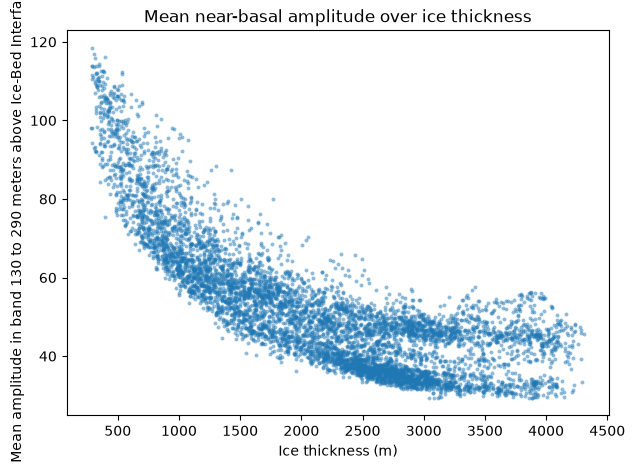

In [24]:
x = metadata["ice_thickness"].values[metadata["survey"] == "IR1HI"]
y = top_mean.numpy()[metadata["survey"] == "IR1HI"]

fig, ax = plt.subplots(figsize = (7, 5))
ax.scatter(x, y, s = 8, alpha = 0.5, linewidths = 0)
ax.set_xlabel("Ice thickness (m)")
ax.set_ylabel("Mean amplitude in band 130 to 290 meters above Ice-Bed Interface")
ax.set_title("Mean near-basal amplitude over ice thickness")
# ax.set_xlim(0, 4000)
plt.show()